In [43]:
# Task 3: Customer Churn Prediction

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [44]:
# Load the Telco Customer Churn dataset
df = pd.read_csv("/content/Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [45]:
# Clean and prepare the customer churn data

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Remove customer ID because it is not a useful predictive feature
df = df.drop(columns=["customerID"])

# Check the target distribution
print("Churn distribution:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

# Separate features and target
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)
print("Missing TotalCharges after conversion:", df["TotalCharges"].isna().sum())

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Features shape: (7043, 19)
Target shape: (7043,)
Missing TotalCharges after conversion: 11


In [46]:
# Split data and define preprocessing

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline ready!")

Training samples: 5634
Testing samples: 1409
Numeric features: 4
Categorical features: 15
Preprocessing pipeline ready!


In [47]:
!pip -q install xgboost imbalanced-learn
print("XGBoost and imbalanced-learn installed!")


XGBoost and imbalanced-learn installed!


In [48]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

models = {
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "XGBoost": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = pred
    probabilities[name] = prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results).sort_values(
    "ROC-AUC", ascending=False
)
display(results_df.round(4))

Training Random Forest...
Training XGBoost...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,XGBoost,0.7984,0.6510,0.5187,0.5774,0.841
0,Random Forest,0.7828,0.6181,0.4759,0.5378,0.822


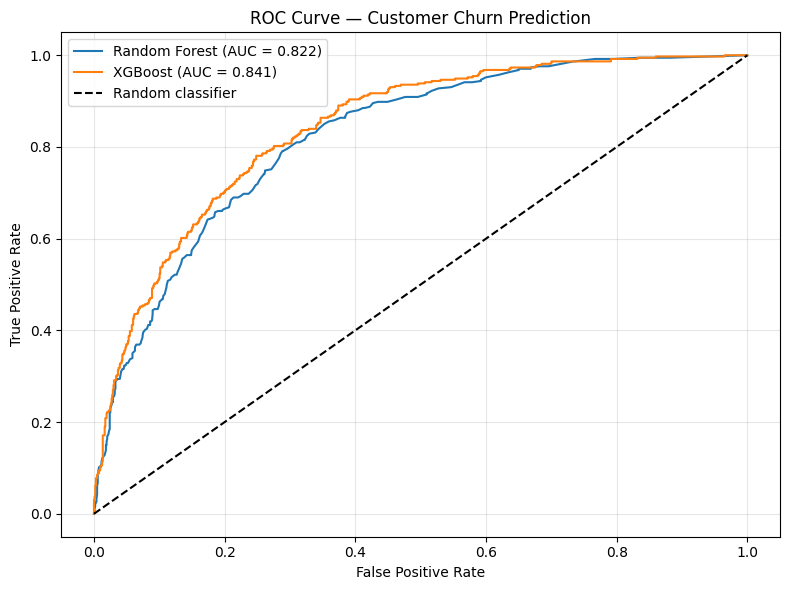

In [49]:
# Compare ROC curves for both models

plt.figure(figsize=(8, 6))

for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_value = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Customer Churn Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

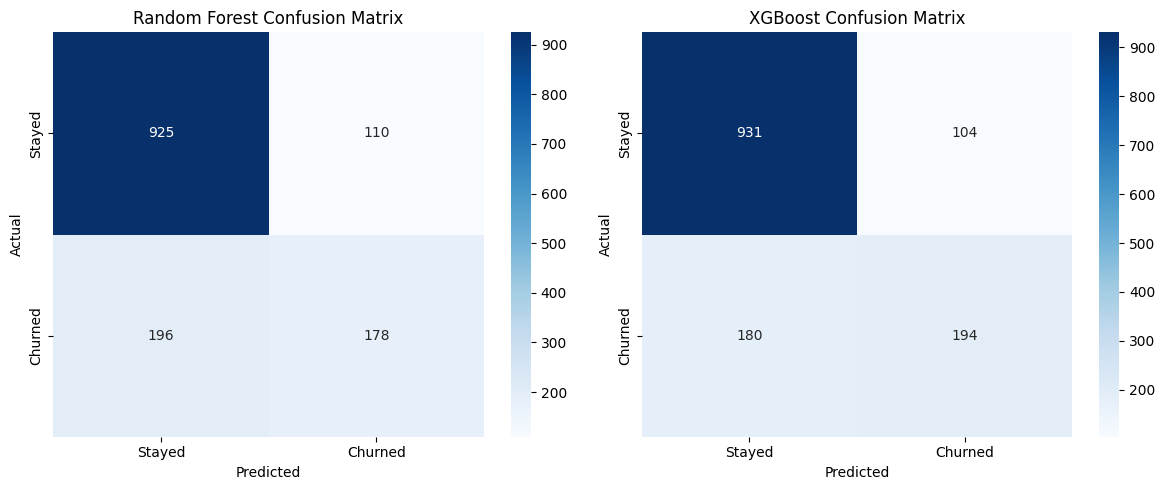

In [50]:
# Confusion matrices for both models

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Stayed", "Churned"],
        yticklabels=["Stayed", "Churned"],
        ax=ax
    )
    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

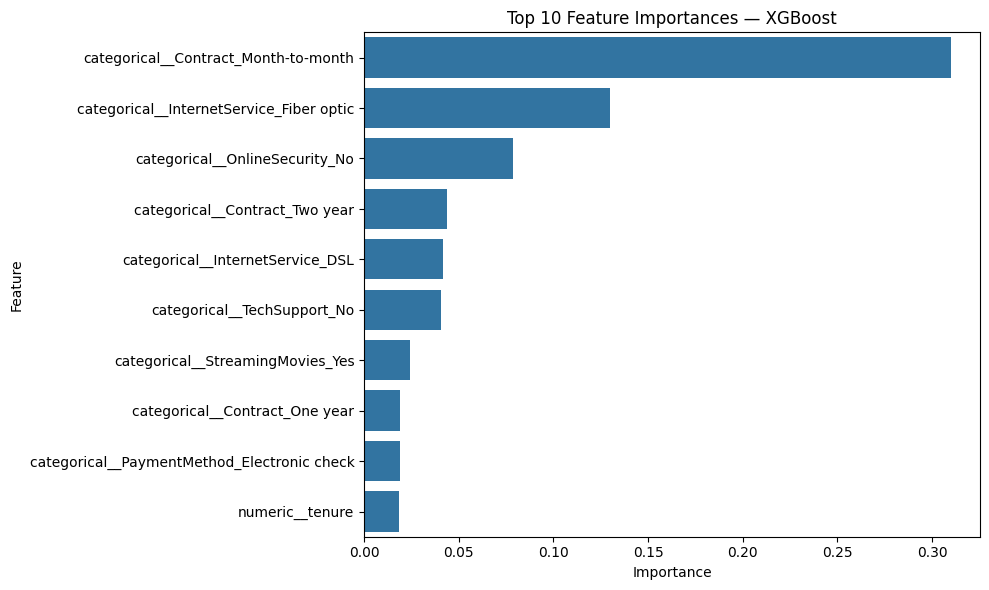

,Feature,Importance
36,categorical__Contract_Month-to-month,0.309811
16,categorical__InternetService_Fiber optic,0.129738
18,categorical__OnlineSecurity_No,0.078418
38,categorical__Contract_Two year,0.043981
15,categorical__InternetService_DSL,0.041635
27,categorical__TechSupport_No,0.040616
35,categorical__StreamingMovies_Yes,0.024340
37,categorical__Contract_One year,0.018950
43,categorical__PaymentMethod_Electronic check,0.018921
1,numeric__tenure,0.018540


In [51]:
# Top 10 most important features from XGBoost

# Get the fitted XGBoost pipeline
xgb_pipeline = models["XGBoost"]

# Get transformed feature names after preprocessing
preprocessor_fitted = xgb_pipeline.named_steps["preprocessor"]
feature_names = preprocessor_fitted.get_feature_names_out()

# Get XGBoost feature importance scores
xgb_model = xgb_pipeline.named_steps["classifier"]
importances = xgb_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)
plt.title("Top 10 Feature Importances — XGBoost")
plt.tight_layout()
plt.show()

display(importance_df)